In [2]:
%pip install -q langchain langchain_core langgraph langchain_openai

Note: you may need to restart the kernel to use updated packages.


In [1]:
import dotenv
import os
dotenv.load_dotenv(".env")

True

In [15]:
import dotenv
from typing import TypedDict, Literal
from urllib.parse import urlparse
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_core.output_parsers import StrOutputParser
from IPython.display import Image, display

In [4]:
from langchain_openai import ChatOpenAI
dotenv.load_dotenv(".env")

raw_base_url = os.getenv("OPENROUTER_BASE_URL", "https://openrouter.ai/api/v1")
openrouter_base_url = raw_base_url.strip().strip('"').strip("'")
parsed = urlparse(openrouter_base_url)
if not parsed.scheme or not parsed.netloc:
    openrouter_base_url = "https://openrouter.ai/api/v1"

llm = ChatOpenAI(
    openai_api_key=os.getenv("OPENROUTER_API_KEY"),
    openai_api_base=openrouter_base_url,
    model_name="gpt-4o-mini-2024-07-18",
)

In [5]:
# Task: write listing copy, check it against the product facts and the Indian size chart,
# improve it if it fails, and stop when it passes or after max_iters rounds.

# Ground truth for the evaluator: a judge with nothing to check against can't verify claims
INDIAN_SIZE_CHART = """Indian size chart (illustrative, for this scenario)
2-3Y: height 92 to 98 cm
3-4Y: height 98 to 104 cm
4-5Y: height 104 to 110 cm
5-6Y: height 110 to 116 cm
6-7Y: height 116 to 122 cm"""

PRODUCT_FACTS = """Name: Dino Print Tee
Fabric: 60% cotton, 40% polyester
Colour: green
Vendor tag: 105 (CN, height in cm)
Indian size label: 4-5Y
Care: machine wash cold"""

BRIEF = "Write for the Diwali sale and make it sound premium."

In [18]:
from typing import Annotated
import operator

class ListingCopy(TypedDict):
    facts: str
    brief: str
    copy: str
    evaluation: Literal["approved", "needs_improvements"]
    feedback: str
    iters: int
    max_iters: int
    copy_history: Annotated[list[str], operator.add]
    review_log: Annotated[list[dict], operator.add]

In [9]:
from pydantic import BaseModel
class CopyReview(BaseModel):
    evaluation: Literal["approved", "needs_improvements"]
    feedback: str

llm_review = llm.with_structured_output(CopyReview)

In [11]:
from langchain_core.prompts import PromptTemplate

def generate_copy(state: ListingCopy):
    tem = PromptTemplate(
        template="""You write product listing copy for Hopscotch, an online kidswear marketplace.
            Brief: {brief}
            Product facts:
            {facts}
            
            Write the listing description in under 60 words.""",
        input_variables=["brief", "facts"]
    )

    chain = tem | llm | StrOutputParser()
    result = chain.invoke({"brief": state["brief"], "facts": state["facts"]})
    return {"copy": result, "copy_history": [result]}

def evaluate_copy(state: ListingCopy):
    tem = PromptTemplate(
        template="""You are a strict listing reviewer. EVALUATE the copy, do not rewrite it.
            Indian size chart:
            {chart}
            
            Product facts (the only source of truth):
            {facts}
            
            COPY TO REVIEW:
            {copy}
            
            RULES. The copy is approved only if ALL are true:
            1. Every product claim (fabric, colour, care, fit) appears in the product facts.
            2. If a size appears, it is the Indian size label for the product. A vendor tag number is never shown as a size.
            3. It is under 60 words.
            4. It contains no placeholders such as [Name].""",
        input_variables=["chart", "facts", "copy"]
    )
    chain = tem | llm_review
    result = chain.invoke({"chart": INDIAN_SIZE_CHART, "facts": state["facts"], "copy": state["copy"]})
    entry = {"round": state["iters"], "verdict": result.evaluation, "feedback": result.feedback}
    return {"evaluation": result.evaluation, "feedback": result.feedback, "review_log": [entry]}

def improve_copy(state: ListingCopy):
    tem = PromptTemplate(
            template=
                """Improve this listing copy so it fixes the reviewer's feedback.
    
                COPY:
                {copy}
                
                FEEDBACK:
                {feedback}
                
                Product facts (the only source of truth):
                {facts}
                
                Rules: fix only what is flagged, add no new claims, stay under 60 words.
                Output only the improved copy.""",
            input_variables=["copy", "feedback", "facts"]
        )
    chain = tem | llm | StrOutputParser()
    response = chain.invoke({"copy": state["copy"], "feedback": state["feedback"], "facts": state["facts"]})
    return {"copy": response, "iters": state["iters"] + 1, "copy_history": [response]}


def is_approved(state: ListingCopy) -> Literal["approved", "needs_improvements", "stop"]:
    if state["evaluation"] == "approved":
        return "approved"
    elif state["iters"] >= state["max_iters"]:
        return "stop"
    else:
        return "needs_improvements"

    

In [21]:
graph = StateGraph(ListingCopy)

graph.add_node("generate_copy", generate_copy)
graph.add_node("evaluate_copy", evaluate_copy)
graph.add_node("improve_copy", improve_copy)

graph.add_edge(START, "generate_copy")
graph.add_edge("generate_copy", "evaluate_copy")
graph.add_conditional_edges("evaluate_copy", is_approved, {"approved": END, "stop": END, "needs_improvements": "improve_copy"})
graph.add_edge("improve_copy", "evaluate_copy")

workflow = graph.compile()

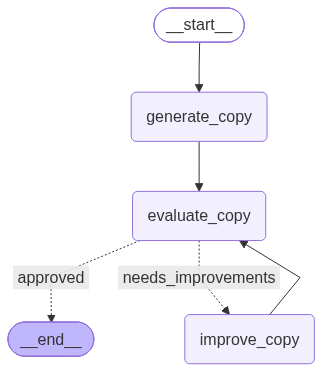

In [22]:
# Draw the graph
display(Image(workflow.get_graph().draw_mermaid_png()))


In [23]:
# Run the loop: start at round 1, allow at most 4 rounds
initial_state = {"facts": PRODUCT_FACTS, "brief": BRIEF, "iters": 1, "max_iters": 4}
final_state = workflow.invoke(initial_state)


In [25]:
# Every round's verdict. If the last one is not approved, the loop stopped at max_iters
# and a person must review the copy before it goes live
for r in final_state["review_log"]:
    print(f"Round {r['round']}: {r['verdict']} | {r['feedback']}")

final_state


Round 1: needs_improvements | The copy has several issues: 1. It does not match the size label; it states 'Perfect for ages 4-5Y' but also uses the Indian size format, which is correct. However, it could mislead customers if they believe age is a common measure. 2. The phrase 'elevate festive wardrobes' is unnecessary and contributes to exceeding 60 words. The total count is 63 words. 3. There are no placeholders, which is good. Overall, it needs to clarify the size reference to avoid confusion.
Round 2: needs_improvements | The copy includes the correct fabric composition, color, and care instructions from the product facts. However, it mentions the size as '4-5Y' but describes 'height 105 cm', which is not the Indian size label provided. Additionally, the copy is 66 words long, exceeding the 60-word limit. Therefore, it needs improvements to comply with the rules.
Round 3: needs_improvements | 1. The copy mentions 'available in Indian size label 4-5Y,' which is correct. However, it s

{'facts': 'Name: Dino Print Tee\nFabric: 60% cotton, 40% polyester\nColour: green\nVendor tag: 105 (CN, height in cm)\nIndian size label: 4-5Y\nCare: machine wash cold',
 'brief': 'Write for the Diwali sale and make it sound premium.',
 'copy': 'Celebrate Diwali in style with our exclusive Dino Print Tee! Crafted from a soft blend of 60% cotton and 40% polyester, this vibrant green tee offers ultimate comfort for your little one. Available only in Indian size label 4-5Y, it’s perfect for festive celebrations and easy to care for with machine wash cold. ',
 'evaluation': 'needs_improvements',
 'feedback': "The copy does not meet all the requirements for approval. While it accurately describes the fabric, colour, and care instructions, it incorrectly refers to size '4-5Y' as the only size available without proper context about size labels. Moreover, it includes a festive theme that may not align with the strict product facts focus. Additionally, it exceeds the word limit, given the festi